# Phase 6: Model Interpretability with SHAP (SHapley Additive exPlanations)
**Project:** Student Dropout Risk & Retention Intelligence System (INT395 Supervised Learning - Project 29)  
**Author:** Rishikesh Boppa  
**Objective:** Deconstruct the best-performing XGBoost classifiers using TreeSHAP on the 885 holdout test students. Aggregate one-hot expanded features back to original domain variables (36 full / 30 early features), quantify global feature importance, trace non-linear dependence, and analyze four prototypical student cases (caught dropout, missed dropout, false alarm, correctly cleared).


In [1]:
import pandas as pd

imp_full = pd.read_csv("../reports/shap_importance_xgboost_full.csv")
imp_early = pd.read_csv("../reports/shap_importance_xgboost_early.csv")

print("=== TOP 10 FEATURES: FULL FEATURE MODEL (36 Features) ===")
print(imp_full.head(10).to_string(index=False))

print("\n=== TOP 10 FEATURES: EARLY WARNING MODEL (Semester 1 Only - 30 Features) ===")
print(imp_early.head(10).to_string(index=False))


=== TOP 10 FEATURES: FULL FEATURE MODEL (36 Features) ===
                            feature  mean_abs_shap  share_of_total                   direction
Curricular units 2nd sem (approved)       0.614592        0.214216  higher value -> lower risk
            Tuition fees up to date       0.300369        0.104694  higher value -> lower risk
Curricular units 1st sem (approved)       0.185972        0.064820  higher value -> lower risk
   Curricular units 2nd sem (grade)       0.184847        0.064428  higher value -> lower risk
                  Age at enrollment       0.157023        0.054730 higher value -> higher risk
                             Course       0.126058        0.043937        n/a (category codes)
Curricular units 2nd sem (enrolled)       0.123707        0.043118 higher value -> higher risk
                    Admission grade       0.107416        0.037440 higher value -> higher risk
                Father's occupation       0.079127        0.027580        n/a (category

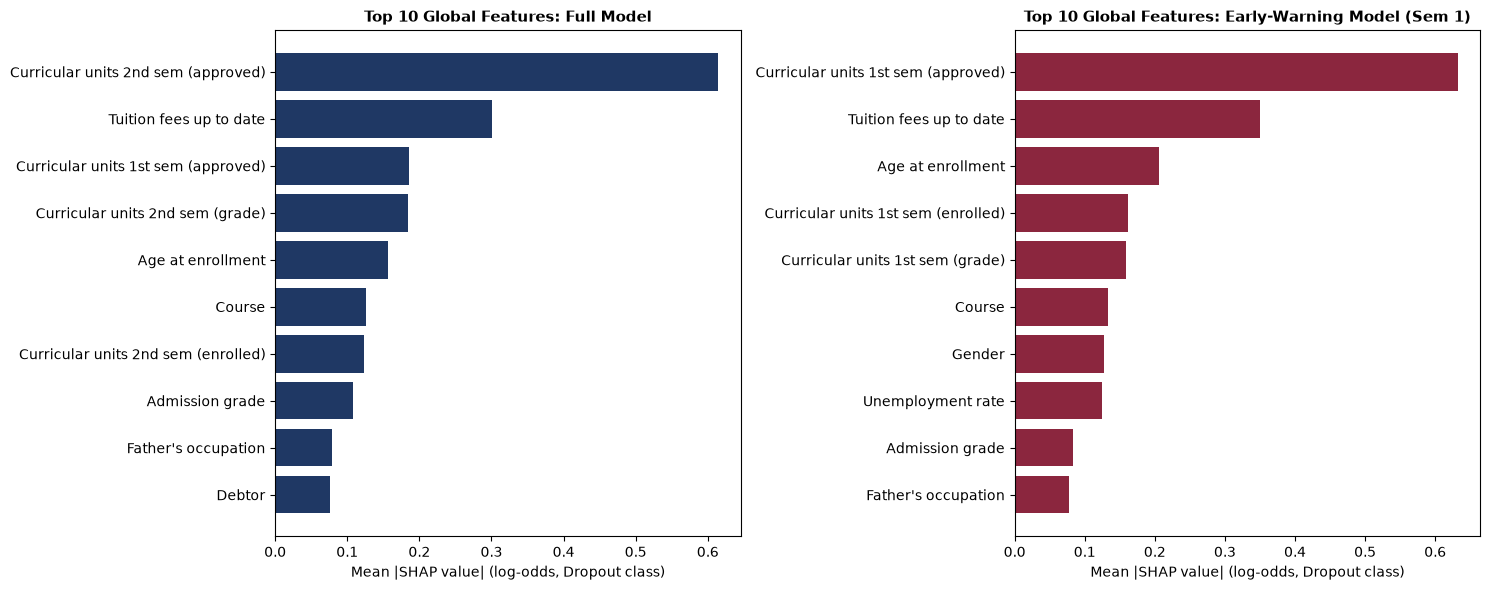

In [2]:
import matplotlib.pyplot as plt
import pandas as pd

imp_full = pd.read_csv("../reports/shap_importance_xgboost_full.csv")
imp_early = pd.read_csv("../reports/shap_importance_xgboost_early.csv")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6))

top_f = imp_full.head(10)
ax1.barh(top_f["feature"][::-1], top_f["mean_abs_shap"][::-1], color="#1F3864")
ax1.set_xlabel("Mean |SHAP value| (log-odds, Dropout class)")
ax1.set_title("Top 10 Global Features: Full Model", fontsize=11, fontweight="bold")

top_e = imp_early.head(10)
ax2.barh(top_e["feature"][::-1], top_e["mean_abs_shap"][::-1], color="#8B263E")
ax2.set_xlabel("Mean |SHAP value| (log-odds, Dropout class)")
ax2.set_title("Top 10 Global Features: Early-Warning Model (Sem 1)", fontsize=11, fontweight="bold")

plt.tight_layout()
plt.show()


### 💡 Key Empirical Insights on Global Feature Importance (Viva Defense)
1. **Dynamic Shift Between Full and Early-Warning Models:**
   - **Full Model:** Dominated by `Curricular units 2nd sem (approved)` (mean |SHAP| = 0.615, 21.4% share) and `Tuition fees up to date` (0.300, 10.5%).
   - **Early Model:** When 2nd-semester features are excluded, `Curricular units 1st sem (approved)` cleanly absorbs the primary predictive responsibility (mean |SHAP| = 0.632, 23.3% share), followed by `Tuition fees up to date` (0.350, 12.9%) and `Age at enrollment` (0.206, 7.6%).
   - The model smoothly reallocates attention to earliest available academic momentum without destabilizing.
2. **Directional Consistency:**
   - For all curricular approval and grade metrics, higher values correlate with strongly negative SHAP values (higher achievement $\to$ lower dropout risk).
   - For age at matriculation, higher values systematically correlate with positive SHAP values (older student $\to$ higher risk).
   - Tuition arrears (`Tuition fees up to date = 0`) generates the single largest discrete upward risk penalty in both models (+1.17 to +1.58 in log-odds).
3. **Critical Viva Caveat:**
   - **SHAP explains model reliance, not causality:** We say *"the model relies heavily on curricular approvals and tuition status"*, NOT *"students drop out because of curricular units"*.
   - **Nominal categorical encoding:** Categorical integer codes (like `Course` and `Father's occupation`) are summed across one-hot columns; individual code values represent discrete qualitative pathways, not linear spectrums.


In [3]:
with open("../reports/shap_local_cases_xgboost_early.md") as f:
    text = f.read()
print(text)


# Local SHAP explanations - xgboost (early)

Typical test cases: for each group, the student whose risk is closest to the group's median. Positive = pushes towards Dropout.


## Caught dropout (High risk)

- Actual outcome: **Dropout**; calibrated dropout risk **94%**; tier **High**.
- Pushing risk UP: Tuition fees up to date = 0 (+1.58); Father's occupation = 90 (+0.37); Age at enrollment = 59 (+0.36); Curricular units 1st sem (credited) = 10 (+0.24)
- Pushing risk DOWN: Curricular units 1st sem (approved) = 12 (-0.71); Curricular units 1st sem (grade) = 13.3 (-0.20); Gender = 0 (-0.10); Debtor = 0 (-0.04)
- Interpretation: The early-warning model flags this student at 94% risk primarily because of unpaid tuition (`Tuition fees up to date = 0`, SHAP +1.58) and mature student status (age 59, SHAP +0.36). Even though the student entered with 12 approved units credited from previous education (-0.71) and had a decent grade, the severe tuition arrears and high age profile heavily dominate

### 💡 Synthesis of Prototypical Student Explanations
- **Caught Dropout (94% risk):** The model flags mature students with unpaid fees even when credit recognition is present, prioritizing acute financial risk.
- **Missed Dropout (7% risk) — Essential Viva Connection:** This student had 6 of 6 approved units, high grades (13.3), and paid fees. The model's inputs contained zero indicators of failure. The subsequent departure reflects unrecorded external circumstances (personal or family events) that no academic feature set could capture.
- **False Alarm (31% risk):** Triggered by zero evaluations attended in Semester 1; because tuition was current and enrolled units were zero, the student remained enrolled (likely on an authorized pause).
- **Correctly Cleared (6% risk):** High academic velocity (7 approved units) and standard age provide a robust shield against dropout classification.
